# 04 · Visualise the results

**Purpose:** show where the fastest-growing villages are and what they have in common.

| | |
|---|---|
| **Inputs** (`outputs/`) | `top100_villages.csv`, `top100_rural_villages.csv` (from notebook 03) |
| **Outputs** | `outputs/maps/top100_map.html` – interactive map · `outputs/figures/top100_charts.png` – charts · `outputs/figures/top100_static_map.png` – static map for the slides |

**Pipeline position:** 01 Prepare → 02 Extract → 03 Score & rank → **04 Visualise**

In [4]:
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
OUT = ROOT / "outputs"
(OUT / "maps").mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(parents=True, exist_ok=True)

top = pd.read_csv(OUT / "top100_villages.csv")
rural = pd.read_csv(OUT / "top100_rural_villages.csv")

COLORS = {"Overall": "#d7301f", "Rural": "#2c7fb8"}   # same colours in the map and the charts
RURAL_KM = 10                                          # must match notebook 03

## Interactive map

- Two layers that can be switched on/off: **top 100 overall** (red) and **top 100 rural** (blue, > 10 km from a city).
- Bigger dot = higher rank. Click a dot for the village's numbers.
- Base maps: OpenStreetMap, plus Esri satellite imagery to see the construction itself. Neither needs an API key.

In [5]:
m = folium.Map(location=[22.5, 79], zoom_start=5, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Satellite").add_to(m)


def popup_html(r):
    # Text shown when a village dot is clicked
    return (f"<b>#{r['rank']} {r['town_village_name']}</b><br>{r['state_name']}<br>"
            f"Score: {r['final_score']}<br>"
            f"Night lights: {r['ntl_2020']:.1f} → {r['ntl_2025']:.1f}<br>"
            f"Built-up: {r['built_2020']:.0%} → {r['built_2025']:.0%}<br>"
            f"Buildings: {r['bldg_2018']:.0f} → {r['bldg_2023']:.0f}<br>"
            f"{r['dist_city_km']} km from {r['nearest_city']}")


def add_layer(df, name, color):
    layer = folium.FeatureGroup(name=name)
    for _, r in df.iterrows():
        folium.CircleMarker(
            [r["lat"], r["lon"]],
            radius=4 + (101 - r["rank"]) / 20,          # rank 1 -> radius 9, rank 100 -> radius 4
            color=color, fill=True, fill_opacity=0.8, weight=1,
            popup=folium.Popup(popup_html(r), max_width=260),
        ).add_to(layer)
    layer.add_to(m)


add_layer(top, "Top 100 overall", COLORS["Overall"])
add_layer(rural, f"Top 100 rural (>{RURAL_KM} km from city)", COLORS["Rural"])
folium.LayerControl(collapsed=False).add_to(m)

m.save(OUT / "maps" / "top100_map.html")
m

## Charts for the presentation

- **Left:** which states the top villages are in (10 states with the most villages on the overall list).
- **Right:** how far the top villages are from the nearest 100k+ city – the dashed line is the 10 km "rural" threshold.

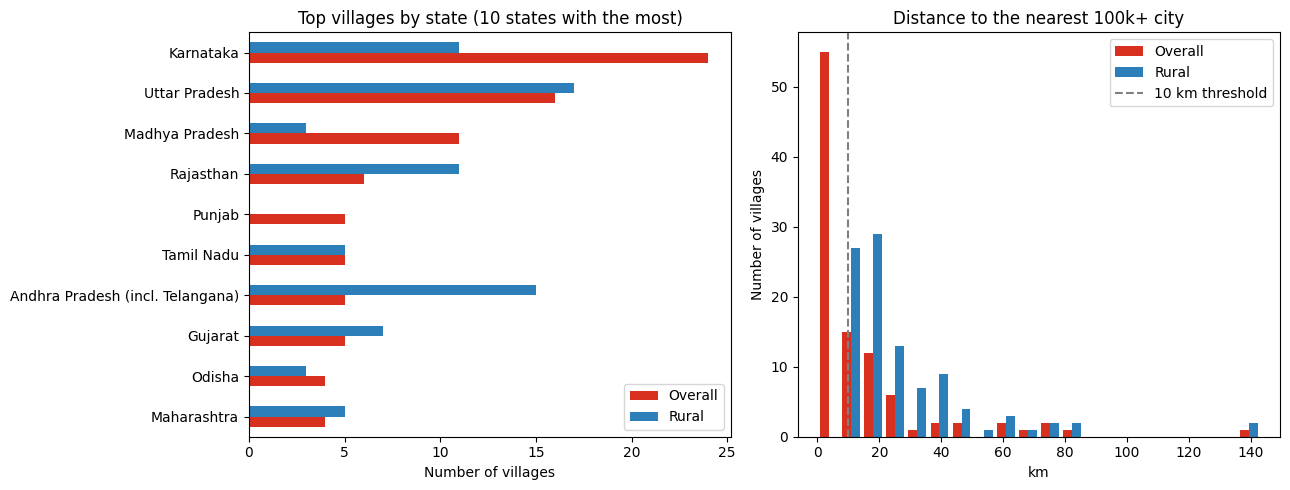

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

counts = pd.DataFrame({"Overall": top["state_name"].value_counts(),
                       "Rural": rural["state_name"].value_counts()}).fillna(0)
counts.sort_values("Overall").tail(10).plot.barh(ax=axes[0], color=[COLORS["Overall"], COLORS["Rural"]])
axes[0].set_title("Top villages by state (10 states with the most)")
axes[0].set_xlabel("Number of villages")
axes[0].set_ylabel("")

axes[1].hist([top["dist_city_km"], rural["dist_city_km"]], bins=20,
             label=["Overall", "Rural"], color=[COLORS["Overall"], COLORS["Rural"]])
axes[1].axvline(RURAL_KM, ls="--", c="grey", label=f"{RURAL_KM} km threshold")
axes[1].set_title("Distance to the nearest 100k+ city")
axes[1].set_xlabel("km")
axes[1].set_ylabel("Number of villages")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUT / "figures" / "top100_charts.png", dpi=200)
plt.show()

## Static map for the slides

A print-friendly map of both lists. The India outline is built from the village boundaries themselves (dissolved by state), so no extra boundary dataset is needed. Takes ~2 minutes.

C:\Users\arpit\AppData\Local\Temp\ipykernel_32712\2623781093.py:10: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  states["geometry"] = states.geometry.buffer(-0.01).simplify(0.02)


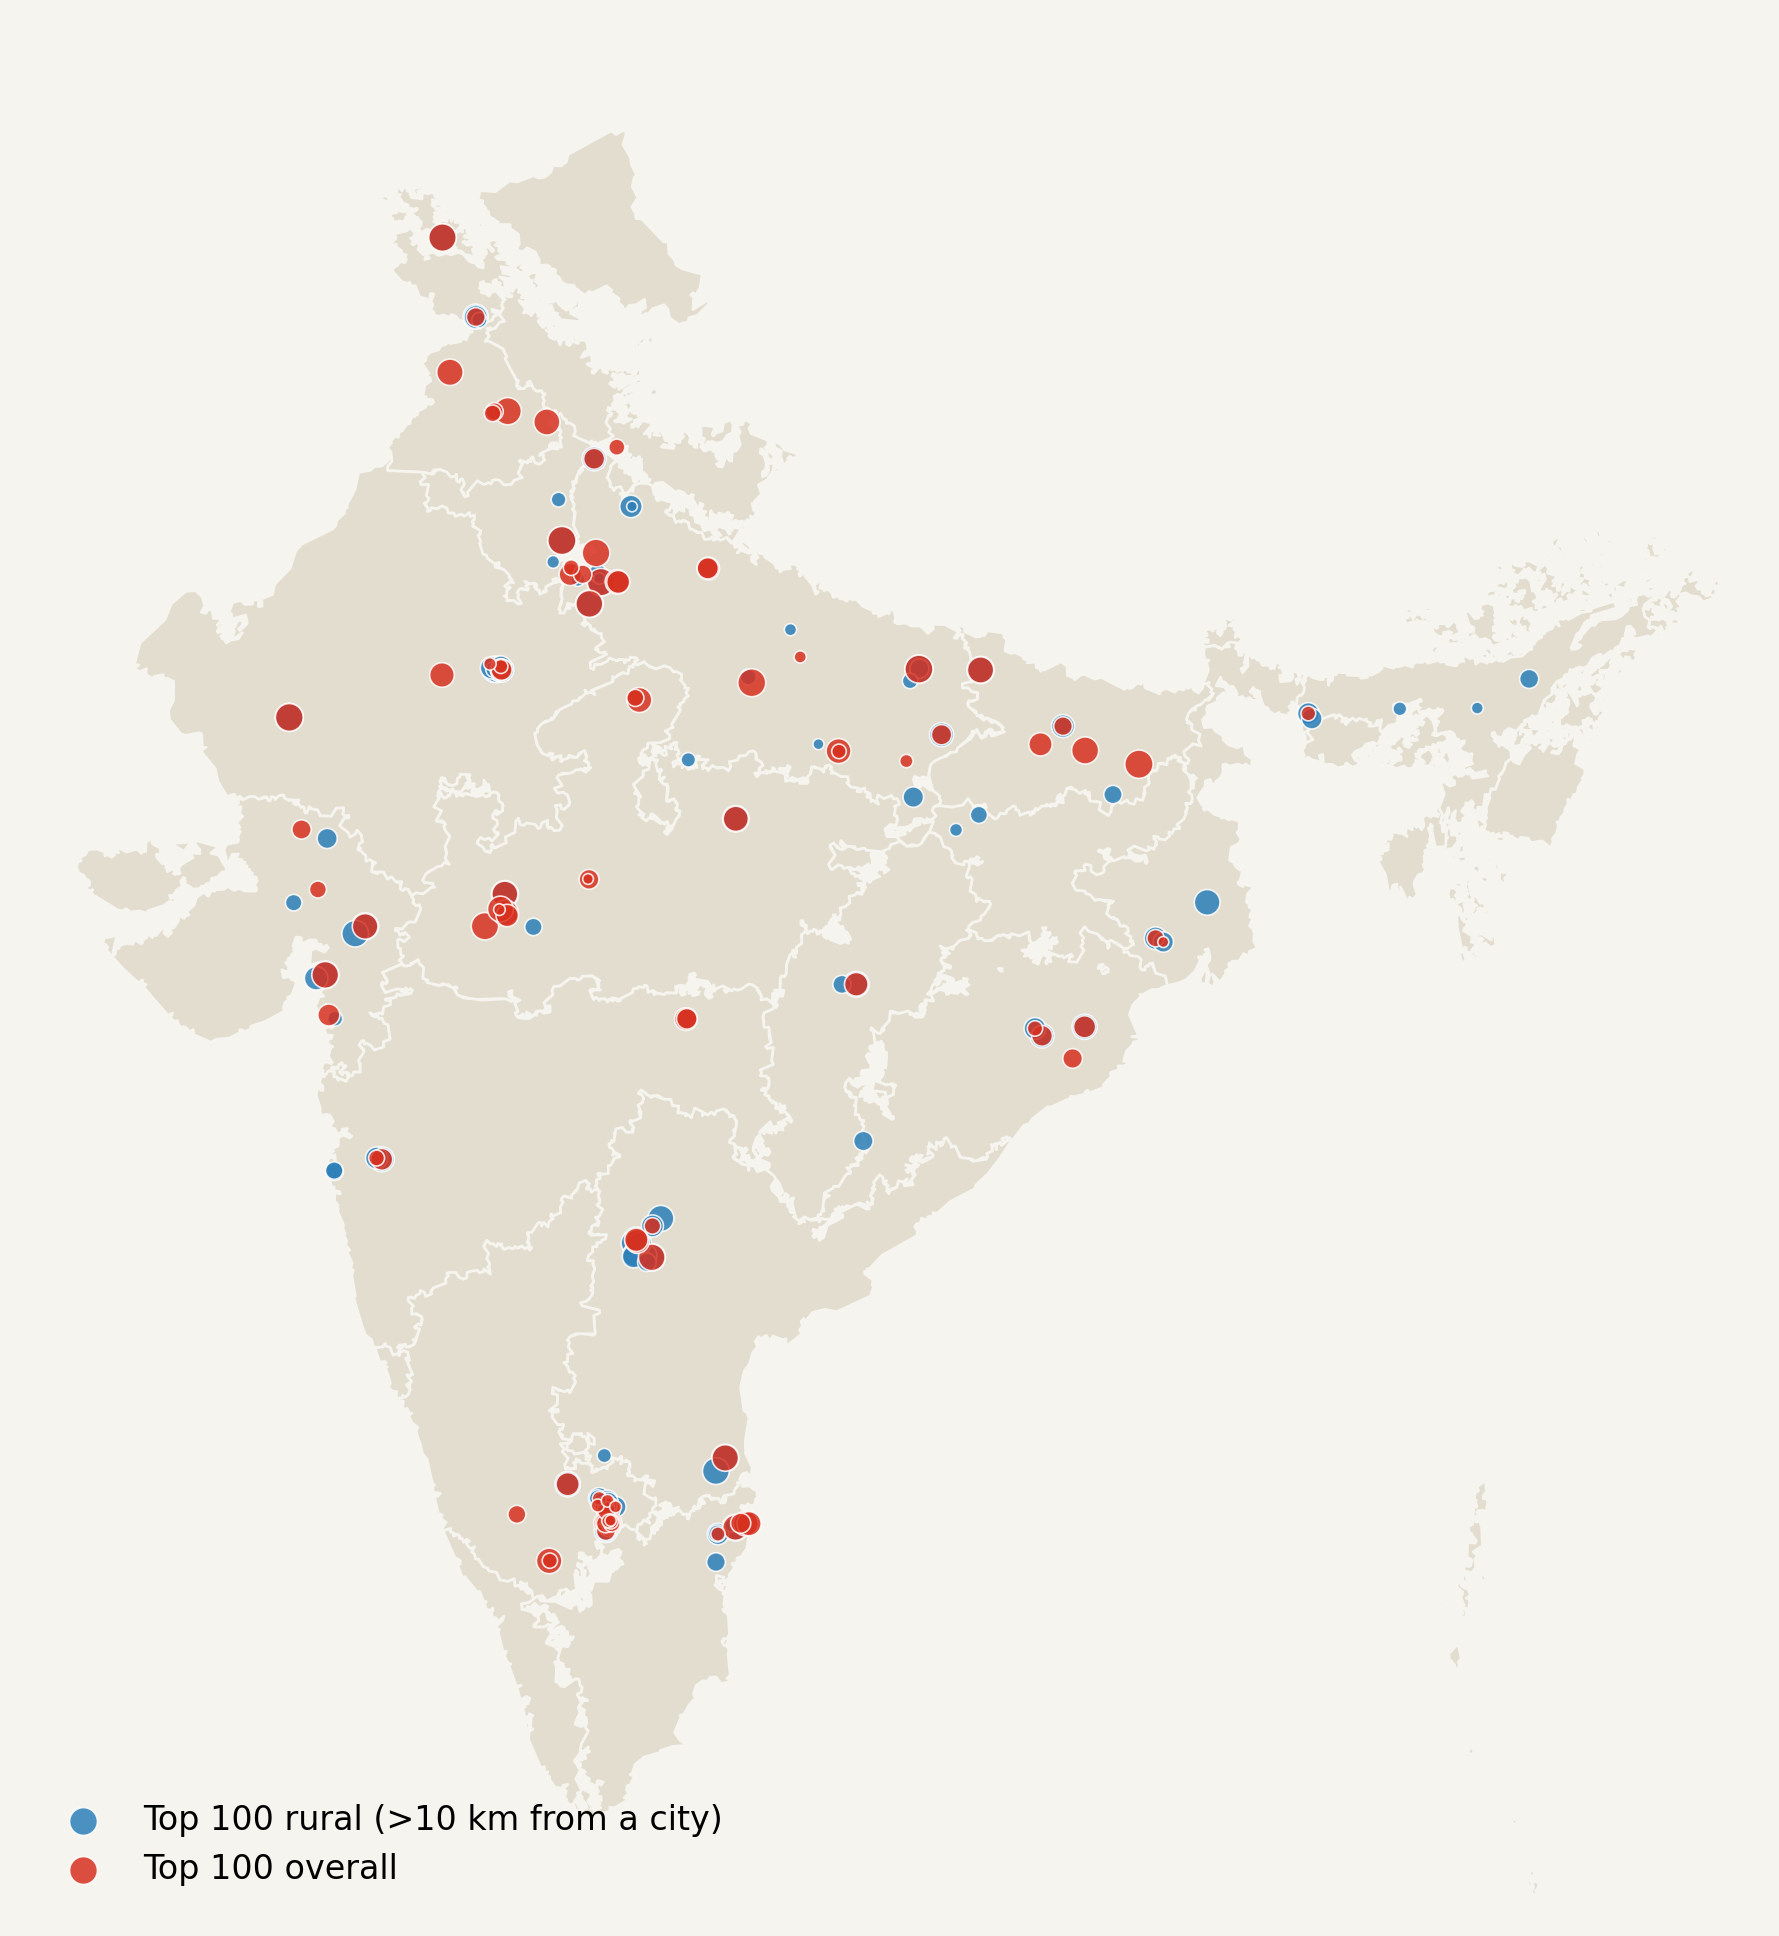

In [7]:
import geopandas as gpd
import shapely
from shapely.geometry import MultiPolygon, Polygon

# Dissolve the 591k village polygons into state outlines. A small buffer closes the gaps
# between neighbouring villages; holes (towns, forests) are filled for a cleaner base map.
v = gpd.read_file(ROOT / "data" / "processed" / "villages_india.gpkg", columns=["pc11_state_id"])
v["geometry"] = shapely.buffer(v.geometry.values, 0.01, quad_segs=1)
states = v.dissolve("pc11_state_id")
states["geometry"] = states.geometry.buffer(-0.01).simplify(0.02)


def fill_holes(geom):
    parts = [geom] if geom.geom_type == "Polygon" else list(geom.geoms)
    parts = [Polygon(p.exterior) for p in parts if p.area > 0.002]   # drop tiny slivers
    return MultiPolygon(parts) if parts else geom


states["geometry"] = states.geometry.apply(fill_holes)

bg = "#F6F4EE"
fig, ax = plt.subplots(figsize=(9, 10), dpi=200)
fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)
states.plot(ax=ax, color="#E2DDCF", edgecolor=bg, linewidth=1.0)
for df, key, label in [(rural, "Rural", f"Top 100 rural (>{RURAL_KM} km from a city)"),
                       (top, "Overall", "Top 100 overall")]:
    ax.scatter(df["lon"], df["lat"], s=14 + (101 - df["rank"]) * 0.9, c=COLORS[key], alpha=0.85,
               edgecolors="white", linewidths=0.6, label=label, zorder=3)   # bigger dot = higher rank
ax.set_axis_off()
ax.set_xlim(67.5, 97.8)
ax.set_ylim(6.5, 37.3)
ax.legend(loc="lower left", frameon=False, fontsize=12, markerscale=1.3)
plt.tight_layout()
plt.savefig(OUT / "figures" / "top100_static_map.png", facecolor=bg, bbox_inches="tight", pad_inches=0.1)
plt.show()